# 07 - Final pipeline

Notebooks 05 and 06 end with two findings that decide this pipeline:

1. RT-DETR-l with default settings (`qb0`) is the best detector: +0.054 AP over YOLO11s
   (`af1`) at the same resolution and number of epochs, better on 24 of 26 clips.
2. The validation curves of both detectors are flat after a few epochs, so more passes over
   the same 1629 frames do not help. The limit is the data, not the training length.

D-FINE (notebook 06) was added after the steps 0-6 had been chosen. It is better than RT-DETR-l
and enters the pipeline through the ensembles of section 3.

Every step below changes one thing and is scored with the same evaluator on the same fold-0
holdout and `val` frames. Data and inference changes are kept apart from model changes.

| Step | Run | Change | Kind |
|---|---|---|---|
| 0 | qb0_rtdetr_l_1152 | best required model (notebook 06) | reference |
| 1 | p2_rtdetr_s5 | every 5th frame of folds 1-2 instead of every 10th (3243 frames), 15 epochs | data |
| 1b | p1_yolo11s_s5 | the same data change for YOLO11s (control) | data |
| 2 | `scripts/infer.py` | inference resolution, NMS on RT-DETR output, flip TTA, tiling | inference |
| 3 | `scripts/infer.py --ensemble` | weighted boxes fusion of several runs | inference |
| 4 | p3_rtdetr_s5_short | p2 with 5 epochs instead of 15, scored with last.pt | schedule |
| 5 | `scripts/temporal.py` | rescoring with the neighbouring frames of the clip | inference |
| 6 | f1_rtdetr_full_s5 | the qb3 recipe (notebook 06) on all 63 train and val clips, for the test set | final fit |
| 7 | f2_rtdetr_full_short | the p3 recipe on all clips, a second final model with another recipe | final fit |
| 8 | f3, f4, f6 | D-FINE-L and D-FINE-X (notebook 06) on all clips | final fit |
| 9 | `scripts/ensemble.py` | WBF of up to 18 runs, then temporal rescoring | inference |

**Same number of iterations.** p1 and p2 see twice as many frames for half the epochs, and
the warm-up and the epochs without mosaic are halved too. The optimiser therefore makes the same
number of steps with the same learning-rate schedule as af1 and qb0, and only the diversity of
the frames changes.

Commands (all from the repository root):

```
python scripts/prepare_data.py --fold 0 --train-step 5
python scripts/train.py configs/pipeline/p2_rtdetr_s5.yaml configs/pipeline/p1_yolo11s_s5.yaml
python scripts/infer.py configs/query_based/qb0_rtdetr_l_1152.yaml --strategy tiles --merge nms
python scripts/infer.py --ensemble <result name> <result name> --weights 2 1
python scripts/train.py configs/pipeline/p3_rtdetr_s5_short.yaml
python scripts/temporal.py configs/query_based/qb0_rtdetr_l_1152.yaml --strategy tiles
python scripts/prepare_data.py --full --train-step 5
python scripts/train.py configs/pipeline/f1_rtdetr_full_s5.yaml
python scripts/infer.py configs/pipeline/f1_rtdetr_full_s5.yaml --strategy tiles --merge nms --test-only
python scripts/ensemble.py <result name> <result name> ... --weights <w> <w> ... --test --name <name>
```

**A caveat on fold 0.** `best.pt` is the epoch with the highest mAP on every 20th fold-0 frame,
so fold-0 numbers of a `best.pt` are slightly optimistic. `val` is never used for any choice
before this notebook and is the cleaner number.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis import paired_comparison, per_clip_ap
from src.common import REPO_ROOT, RUNS_DIR
from src.evaluate import coco_evaluate
from src.predict import EVAL_SETS
from src.train_tools import load_config
from scripts.ensemble import fuse, to_detections

INFERENCE_DIR = RUNS_DIR / "inference"
pd.set_option("display.precision", 4)

D:\Studying_2027_1\Artificial_Intelligence\cv-object-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1108 19:42:01.240000 51492 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
def load_runs(family):
    found = {}
    for config_path in sorted((REPO_ROOT / "configs" / family).glob("*.yaml")):
        cfg = load_config(config_path)
        run_dir = RUNS_DIR / family / cfg["name"]
        if (run_dir / "metrics.json").exists():
            found[cfg["name"]] = {"cfg": cfg, "dir": run_dir,
                                  "metrics": json.loads((run_dir / "metrics.json").read_text())}
    return found


def load_inference_results():
    found = {}
    for path in sorted(INFERENCE_DIR.glob("*/metrics.json")):
        found[path.parent.name] = {"dir": path.parent, "metrics": json.loads(path.read_text())}
    return found


def metrics_table(entries):
    rows = []
    for name, entry in entries.items():
        fold0, val = entry["metrics"]["fold0"], entry["metrics"]["val"]
        rows.append({"run": name, "AP": fold0["AP"], "AP50": fold0["AP50"], "AP_small": fold0["AP_small"],
                     "val_AP": val["AP"], "val_AP50": val["AP50"], "val_AP_small": val["AP_small"],
                     "ms_per_image": val["ms_per_image"]})
    return pd.DataFrame(rows).set_index("run")


def clip_ap_of(detection_files):
    # detection_files maps eval set -> path of a COCO detections file
    ap = {}
    for eval_set, path in detection_files.items():
        detections = json.loads(path.read_text())
        for clip, value in per_clip_ap(EVAL_SETS[eval_set][1], detections).items():
            ap[f"{eval_set}/{clip}"] = value
    return ap


def compare(clip_ap, reference):
    table = paired_comparison(clip_ap, reference=reference).drop(index=reference)
    table["significant"] = table["mean_diff"].abs() >= 2 * table["std_err"]
    return table


families = ["anchor_free", "query_based", "pipeline"]
runs = {name: run for family in families for name, run in load_runs(family).items()}
inference = load_inference_results()
print("training runs:", list(runs))
print("inference results:", list(inference))

training runs: ['af0_baseline_640', 'af1_imgsz1152', 'af2_p2_1152', 'af3_nwd_1152', 'af4_topk15_1152', 'af4_topk5_1152', 'qb0_rtdetr_l_1152', 'qb1_bblr_1152', 'qb2_q500_1152', 'qb3_bblr_nobiaswarm_1152', 'qb4_q500_default_1152', 'qb5_dfine_l_1152', 'qb6_dfine_x_1152', 'qb7_dfine_x_crop035', 'p1_yolo11s_s5', 'p2_rtdetr_s5', 'p3_rtdetr_s5_short']
inference results: ['af4_topk5_1152_plain_1152', 'c1_rtdetr_p2_s5_short_plain_1152', 'c2_rtdetr_p2_open_s5_short_plain_1152', 'ens_qb0_rtdetr_l_1152_plain_1152+af4_topk5_1152_plain_1152', 'ens_qb3_bblr_nobiaswarm_1152_plain_1152+p3_rtdetr_s5_short_plain_1152', 'p2_rtdetr_s5_plain_1152', 'p3_rtdetr_s5_short_plain_1152', 'qb0_rtdetr_l_1152_flip_nms_1152', 'qb0_rtdetr_l_1152_flip_wbf_1152', 'qb0_rtdetr_l_1152_nms_1152', 'qb0_rtdetr_l_1152_plain_1152', 'qb0_rtdetr_l_1152_plain_1344', 'qb0_rtdetr_l_1152_plain_1536', 'qb0_rtdetr_l_1152_tiles_flip_nms_1152', 'qb0_rtdetr_l_1152_tiles_nms_1152', 'qb0_rtdetr_l_1152_tiles_nms_grid3_1152', 'qb0_rtdetr_l_115

## 1. Data: more distinct frames at the same number of iterations

Each pipeline run is paired with the run it changes. `delta` is the change of the metric.

In [3]:
data_pairs = {"p1_yolo11s_s5": "af1_imgsz1152", "p2_rtdetr_s5": "qb0_rtdetr_l_1152"}
data_pairs = {new: old for new, old in data_pairs.items() if new in runs and old in runs}

table = metrics_table(runs)
data_rows = []
for new, old in data_pairs.items():
    for metric in ["AP", "AP_small", "val_AP", "val_AP_small"]:
        data_rows.append({"run": new, "reference": old, "metric": metric, "reference_value": table.loc[old, metric],
                          "new_value": table.loc[new, metric], "delta": table.loc[new, metric] - table.loc[old, metric]})
pd.DataFrame(data_rows).set_index(["run", "metric"])

reference  reference_value  new_value  \
run           metric                                                        
p1_yolo11s_s5 AP                af1_imgsz1152           0.2343     0.2351   
              AP_small          af1_imgsz1152           0.0671     0.0678   
              val_AP            af1_imgsz1152           0.1877     0.1856   
              val_AP_small      af1_imgsz1152           0.1214     0.0945   
p2_rtdetr_s5  AP            qb0_rtdetr_l_1152           0.2957     0.2998   
              AP_small      qb0_rtdetr_l_1152           0.0842     0.0928   
              val_AP        qb0_rtdetr_l_1152           0.2534     0.2486   
              val_AP_small  qb0_rtdetr_l_1152           0.1342     0.1236   

                             delta  
run           metric                
p1_yolo11s_s5 AP            0.0008  
              AP_small      0.0007  
              val_AP       -0.0021  
              val_AP_small -0.0270  
p2_rtdetr_s5  AP            0.0041  
              AP_small      0.0086  
              val_AP       -0.0048  
              val_AP_small -0.0106

Validation mAP during training against the number of optimiser steps (epochs times frames per
epoch, in units of one pass over the 1629 frames of the step-10 set). Both runs of a pair end
at the same point.

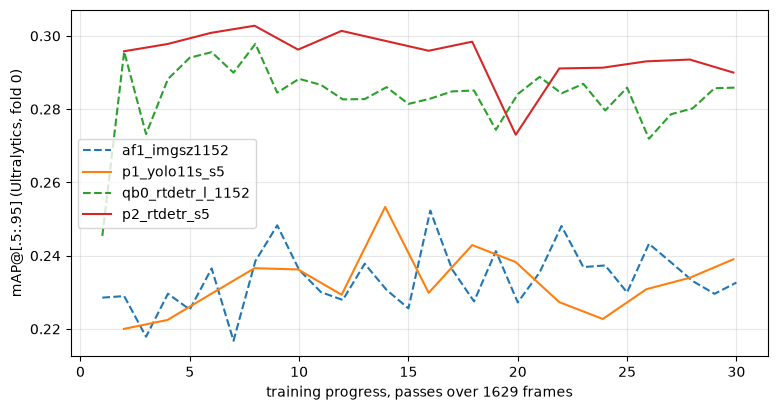

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for new, old in data_pairs.items():
    for name in (old, new):
        curve = pd.read_csv(runs[name]["dir"] / "results.csv")
        curve.columns = curve.columns.str.strip()
        n_frames = len(list((REPO_ROOT / Path(runs[name]["cfg"]["data"]).parent / "images" / "train").glob("*.jpg")))
        steps = curve["epoch"] * n_frames / 1629
        ax.plot(steps, curve["metrics/mAP50-95(B)"], "-" if name == new else "--", label=name)
ax.set_xlabel("training progress, passes over 1629 frames")
ax.set_ylabel("mAP@[.5:.95] (Ultralytics, fold 0)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [5]:
data_clip_ap = {name: clip_ap_of({s: runs[name]["dir"] / f"predictions_{s}.json" for s in EVAL_SETS})
                for pair in data_pairs.items() for name in pair}
for new, old in data_pairs.items():
    print(f"{new} against {old}")
    display(compare({new: data_clip_ap[new], old: data_clip_ap[old]}, reference=old))

p1_yolo11s_s5 against af1_imgsz1152


,mean_diff,std_err,clips_better,clips_worse,significant
p1_yolo11s_s5,-0.005,0.0088,13.0,13.0,False


p2_rtdetr_s5 against qb0_rtdetr_l_1152


,mean_diff,std_err,clips_better,clips_worse,significant
p2_rtdetr_s5,0.0149,0.0111,12.0,14.0,False


**Finding.** Twice as many frames at the same number of iterations change nothing that is
larger than the noise, for either detector (YOLO11s: -0.005 +- 0.009 per clip, 13 clips better
and 13 worse; RT-DETR: +0.015 +- 0.011, 12 better and 14 worse). Neighbouring frames of a clip
are almost identical, so every 5th frame adds little that every 10th frame did not already show.
More data can only help through new clips, which is what the final fit adds.

## 2. Inference strategies on one trained model

All strategies run on the same checkpoint, so every difference comes from inference alone.
`ms_per_image` is the wall time of all passes and of the merging (batch 1, FP16).

| Strategy | What it does |
|---|---|
| plain | one pass on the full frame (as in notebooks 05 and 06) |
| nms | plain + class-wise NMS (IoU 0.7): removes duplicates the one-to-one matching left |
| plain at 1344 / 1536 | the model trained at 1152 px is run on a larger input |
| flip | full frame + mirrored frame, merged by NMS or by weighted boxes fusion (WBF) |
| tiles | full frame + 2x2 tiles with 20% overlap, each at 1152 px (about 1.7x zoom); boxes cut by an inner tile border are dropped (SAHI, arXiv:2202.06934) |
| tiles_flip | tiles + the mirrored full frame |
| tiles grid 3 | full frame + 3x3 tiles (about 2.4x zoom) |

In [6]:
strategy_results = {name: r for name, r in inference.items() if "config" in r["metrics"]}
strategies = metrics_table(strategy_results)
strategies.insert(0, "model", [Path(r["metrics"]["config"]).stem for r in strategy_results.values()])
strategies.sort_values(["model", "AP"])

,model,AP,AP50,AP_small,val_AP,val_AP50,val_AP_small,ms_per_image
run,,,,,,,,
af4_topk5_1152_plain_1152,af4_topk5_1152,0.2378,0.4430,0.0699,0.1982,0.3851,0.1004,20.9307
c1_rtdetr_p2_s5_short_plain_1152,c1_rtdetr_p2_s5_short,0.2938,0.5287,0.0850,0.2429,0.4669,0.1457,62.0752
c2_rtdetr_p2_open_s5_short_plain_1152,c2_rtdetr_p2_open_s5_short,0.2906,0.5327,0.0839,0.2739,0.5186,0.1463,63.2506
p2_rtdetr_s5_plain_1152,p2_rtdetr_s5,0.2998,0.5473,0.0928,0.2486,0.4758,0.1236,55.7392
p3_rtdetr_s5_short_plain_1152,p3_rtdetr_s5_short,0.2953,0.5339,0.0891,0.2822,0.5226,0.1286,65.8930
qb0_rtdetr_l_1152_tiles_wbf_1152,qb0_rtdetr_l_1152,0.2781,0.5396,0.0844,0.2442,0.5034,0.1358,303.0187
qb0_rtdetr_l_1152_flip_wbf_1152,qb0_rtdetr_l_1152,0.2879,0.5341,0.0799,0.2440,0.4760,0.1027,156.5137
qb0_rtdetr_l_1152_nms_1152,qb0_rtdetr_l_1152,0.2954,0.5445,0.0843,0.2532,0.4849,0.1342,60.0989
qb0_rtdetr_l_1152_plain_1152,qb0_rtdetr_l_1152,0.2957,0.5434,0.0842,0.2534,0.4844,0.1342,63.5363


In [7]:
# Paired per-clip comparison against the plain pass of the same model
for model_name, group in strategies.groupby("model"):
    config = strategy_results[group.index[0]]["metrics"]["config"]
    plain = f"{model_name}_plain_{load_config(REPO_ROOT / config)['imgsz']}"
    clip_ap = {name: clip_ap_of({s: inference[name]["dir"] / f"detections_{s}.json" for s in EVAL_SETS})
               for name in group.index}

    # Without a separate plain pass, the predictions of the training run are the plain pass
    if plain not in clip_ap and model_name in runs:
        clip_ap[plain] = clip_ap_of({s: runs[model_name]["dir"] / f"predictions_{s}.json" for s in EVAL_SETS})
    if plain not in clip_ap or len(clip_ap) < 2:
        continue
    print(f"{model_name}: against {plain}")
    display(compare(clip_ap, reference=plain))

qb0_rtdetr_l_1152: against qb0_rtdetr_l_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
qb0_rtdetr_l_1152_flip_nms_1152,0.0089,0.0031,17.0,9.0,True
qb0_rtdetr_l_1152_flip_wbf_1152,-0.0094,0.0035,9.0,17.0,True
qb0_rtdetr_l_1152_nms_1152,-0.0003,0.0001,11.0,15.0,True
qb0_rtdetr_l_1152_plain_1344,0.0084,0.0025,19.0,7.0,True
qb0_rtdetr_l_1152_plain_1536,0.0103,0.0045,17.0,9.0,True
qb0_rtdetr_l_1152_tiles_flip_nms_1152,0.0253,0.0036,26.0,0.0,True
qb0_rtdetr_l_1152_tiles_nms_1152,0.0212,0.0033,26.0,0.0,True
qb0_rtdetr_l_1152_tiles_nms_grid3_1152,0.0121,0.0037,19.0,7.0,True
qb0_rtdetr_l_1152_tiles_nms_minw1600_1152,0.0179,0.0036,22.0,0.0,True
qb0_rtdetr_l_1152_tiles_wbf_1152,-0.0069,0.0058,9.0,17.0,False


qb3_bblr_nobiaswarm_1152: against qb3_bblr_nobiaswarm_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
qb3_bblr_nobiaswarm_1152_tiles_nms_1152,0.0198,0.0042,23.0,3.0,True
qb3_bblr_nobiaswarm_1152_tiles_nms_minw1600_1152,0.0189,0.0043,21.0,1.0,True


qb5_dfine_l_1152: against qb5_dfine_l_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
qb5_dfine_l_1152_plain_1344,-0.0031,0.0036,13.0,13.0,False
qb5_dfine_l_1152_plain_1536,-0.0112,0.0057,7.0,19.0,False


**Finding.** Tiling with NMS is the only large gain: +0.021 +- 0.003 per-clip AP, better on all 26
clips, at 4.5 times the inference time. The zoomed tiles find small objects the full frame
misses (val AP_small 0.156 against 0.134). A larger input without tiles helps less (+0.008 at
1344 px, +0.010 at 1536 px), and flip TTA helps a little (+0.009). NMS on the plain RT-DETR
output changes nothing, as in notebook 06.

The gain carries over to the better model: tiles on qb3 give +0.020 +- 0.004 over its plain pass
(23 of 26 clips better), and qb3 with tiles is the best result on both sets (fold 0 0.325, val
0.287). Against qb0 with tiles it is still +0.009 +- 0.005, so the two gains add up.

More of the same does not help: adding the mirrored frame to the tiles (fold 0 0.318, val 0.271)
or a 3x3 grid (2.4x zoom; 0.315 / 0.264, twice the time) is not better than the 2x2 tiles
(0.317 / 0.275). At 2.4x zoom the tiles are small, and large objects are cut by more borders.

WBF is worse than NMS for both flip and tiles. WBF lowers the score of a box found by only some
of the parts, which is right for an ensemble of models that all see the whole frame, but here a
small object is often found only in its tile, so exactly the boxes tiling is meant to add are
pushed down. It also averages the boxes of a cluster, which merges neighbouring cars in dense
parking lots.

### Tiles and the frame width

On our sets tiles gave +0.020 to +0.026, but on the public leaderboard they gave almost nothing to
the final model (0.2816 with temporal rescoring, 0.2812 without tiles, section 8). The test frames
are narrower than ours, so we looked at the frame width.

In [8]:
from PIL import Image

from src.temporal import frames_table


def clip_widths(split):
    # All frames of a clip have the same size
    frames = frames_table(split)
    return {clip: Image.open(group["path"].iloc[0]).size[0] for clip, group in frames.groupby("clip")}


widths = {split: clip_widths(split) for split in ["train", "val", "test"]}
display(pd.DataFrame({split: pd.Series(w).value_counts() for split, w in widths.items()})
        .fillna(0).astype(int).rename_axis("frame width").sort_index())

QB3 = "qb3_bblr_nobiaswarm_1152"
tile_gain = pd.DataFrame({
    "plain": clip_ap_of({s: runs[QB3]["dir"] / f"predictions_{s}.json" for s in EVAL_SETS}),
    "tiles": clip_ap_of({s: inference[f"{QB3}_tiles_nms_1152"]["dir"] / f"detections_{s}.json" for s in EVAL_SETS}),
})
tile_gain["gain"] = tile_gain["tiles"] - tile_gain["plain"]
tile_gain["width"] = [widths[EVAL_SETS[key.split("/")[0]][0]][key.split("/")[1]] for key in tile_gain.index]
tile_gain.groupby("width")["gain"].agg(["mean", "count"])

,train,val,test
frame width,,,
680,0,0,3
960,0,0,5
1344,11,2,7
1360,1,0,18
1904,30,2,4
1920,1,0,11
2688,11,1,0
2720,2,1,0
3840,0,1,0


,mean,count
width,,
1344,0.0059,4
1904,0.0186,13
2688,0.0271,6
2720,0.0115,2
3840,0.0673,1


**Finding.** 33 of the 48 test clips are at most 1360 px wide (down to 680 px), while most of our
training and evaluation clips are 1904 px or wider. On qb3 the gain of tiles grows with the frame
width: +0.006 per clip at 1344 px (only 4 clips), +0.019 at 1904 px, +0.067 at 3840 px.

Our first explanation was wrong. We expected tiles to help only wide frames, because a wide frame
loses more pixels when it is scaled to 1152 px, so we used tiles only on frames at least 1600 px
wide (`--tile-min-width 1600`). The public score fell to 0.2732, below both no tiles and all tiles.
The file was checked frame by frame and is correct.

All frames of a clip have the same width and temporal rescoring works inside a clip, so every
width rule is a row mix of the submissions with and without tiles. Public scores with temporal
rescoring, f1:

| Tiles on | Public score | Against no tiles |
|---|---|---|
| no frames | 0.2812 | |
| wide frames only (1296 frames) | 0.2732 | -0.008 |
| all frames | 0.2816 | +0.000 |
| narrow frames only (2515 frames) | 0.2894 | +0.008 |

The two effects add up: the score of the last row was predicted as 0.2897 before it was submitted.
On the public test frames tiles help narrow frames and hurt wide ones, the opposite of our
evaluation sets, and we do not know why. The final pipeline uses tiles only on frames narrower
than 1600 px (`--tile-max-width 1600`). This rule was chosen on the public leaderboard and has no
support from our folds, so it may not hold on the private part. That is why the second final
submission uses tiles on all frames: the two differ only on the wide frames.

## 3. Ensembles

Weighted boxes fusion (Solovyev et al., arXiv:1910.13302, implemented in `src/inference.py`):
boxes of the same class from different sources are clustered by IoU > 0.55, averaged with
their scores as weights, and the fused score is lowered when only some of the sources found
the object.

In [9]:
ensemble_results = {name: r for name, r in inference.items() if "sources" in r["metrics"]}
if ensemble_results:
    ensembles = metrics_table(ensemble_results).drop(columns="ms_per_image")
    ensembles.insert(0, "weights", [str(r["metrics"]["weights"]) for r in ensemble_results.values()])
    display(ensembles.sort_values("AP"))

    # Paired comparison of every ensemble against its best source
    for name, result in ensemble_results.items():
        names = [name, *result["metrics"]["sources"]]
        clip_ap = {n: clip_ap_of({s: inference[n]["dir"] / f"detections_{s}.json" for s in EVAL_SETS}) for n in names}
        best_source = max(result["metrics"]["sources"], key=lambda n: inference[n]["metrics"]["val"]["AP"])
        print(f"{name}: against {best_source}")
        display(compare(clip_ap, reference=best_source))

,weights,AP,AP50,AP_small,val_AP,val_AP50,val_AP_small
run,,,,,,,
ens_qb0_rtdetr_l_1152_plain_1152+af4_topk5_1152_plain_1152,"[2.0, 1.0]",0.2918,0.5443,0.0788,0.2498,0.4912,0.1296
ens_qb3_bblr_nobiaswarm_1152_plain_1152+p3_rtdetr_s5_short_plain_1152,None,0.3018,0.5446,0.0851,0.2794,0.5251,0.1247


ens_qb0_rtdetr_l_1152_plain_1152+af4_topk5_1152_plain_1152: against qb0_rtdetr_l_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
ens_qb0_rtdetr_l_1152_plain_1152+af4_topk5_1152_plain_1152,-0.0003,0.0033,12.0,14.0,False
af4_topk5_1152_plain_1152,-0.0419,0.0073,2.0,24.0,True


ens_qb3_bblr_nobiaswarm_1152_plain_1152+p3_rtdetr_s5_short_plain_1152: against p3_rtdetr_s5_short_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
ens_qb3_bblr_nobiaswarm_1152_plain_1152+p3_rtdetr_s5_short_plain_1152,0.0015,0.005,16.0,10.0,False
qb3_bblr_nobiaswarm_1152_plain_1152,-0.0036,0.005,11.0,15.0,False


**Finding.** Fusing RT-DETR with the best YOLO11s run does not help (-0.000 +- 0.003): YOLO11s
is worse on 24 of 26 clips, and its boxes add false positives about as often as missed objects.
Two RT-DETR runs with different recipes (qb3 and p3 of section 4, which are equally good) give
+0.002 +- 0.005 over p3 (16 clips better, 10 worse; val AP 0.279 against 0.282), again not
larger than the noise, at twice the inference time. The errors
of two RT-DETR-l runs from the same COCO weights are too similar for fusion to fix them.

### Many runs at once

`scripts/ensemble.py` fuses the saved detections of any number of runs with the same WBF (IoU
0.65; boxes below score 0.05 are dropped when a run is loaded). Two runs from the same COCO
weights make similar errors (above), but the eleven RT-DETR runs below differ in recipe, data,
schedule, architecture (c1 and c2 of notebook 08) and training folds (notebook 09), and D-FINE is
another model with other pretraining. Only runs that did not train on the `val` clips can be
scored, so this table is on `val` only (571 frames of 7 clips), and the paired comparison over 7
clips is weaker than over 26.

In [10]:
RTDETR_RUNS = [f"{name}_plain_1152" for name in [
    "qb0_rtdetr_l_1152", "qb0_rtdetr_l_1152_fold1", "qb0_rtdetr_l_1152_fold2",
    "qb3_bblr_nobiaswarm_1152", "qb3_bblr_nobiaswarm_1152_fold1", "qb3_bblr_nobiaswarm_1152_fold2",
    "qb4_q500_default_1152", "p2_rtdetr_s5", "p3_rtdetr_s5_short",
    "c1_rtdetr_p2_s5_short", "c2_rtdetr_p2_open_s5_short"]]
L, X, X2 = "qb5_dfine_l_1152_plain_1152", "qb6_dfine_x_1152_plain_1152", "qb7_dfine_x_crop035_plain_1152"
ONES = [1] * len(RTDETR_RUNS)
VAL_ENSEMBLES = {
    "11 RT-DETR": (RTDETR_RUNS, ONES),
    "11 RT-DETR + D-FINE-L w3": ([L, *RTDETR_RUNS], [3, *ONES]),
    "11 RT-DETR + D-FINE-X w6 + L w3": ([X, L, *RTDETR_RUNS], [6, 3, *ONES]),
    "11 RT-DETR + D-FINE-X qb6 w4, qb7 w4 + L w3": ([X, X2, L, *RTDETR_RUNS], [4, 4, 3, *ONES]),
}
SINGLE = {"p3 alone": "p3_rtdetr_s5_short_plain_1152", "D-FINE-L alone": L, "D-FINE-X alone": X}

val_gt = EVAL_SETS["val"][1]
val_ids = [image["id"] for image in json.loads(val_gt.read_text())["images"]]
val_rows, val_clip_ap = [], {}
for name, run in SINGLE.items():
    detections = json.loads((INFERENCE_DIR / run / "detections_val.json").read_text())
    val_rows.append({"ensemble": name, "runs": 1, **{k: inference[run]["metrics"]["val"][k] for k in ["AP", "AP50", "AP_small"]}})
    val_clip_ap[name] = per_clip_ap(val_gt, detections)
for name, (sources, weights) in VAL_ENSEMBLES.items():
    detections = to_detections(fuse(sources, "val", val_ids, weights, 0.65, 0.05))
    metrics = coco_evaluate(val_gt, detections)
    val_rows.append({"ensemble": name, "runs": len(sources), **{k: metrics[k] for k in ["AP", "AP50", "AP_small"]}})
    val_clip_ap[name] = per_clip_ap(val_gt, detections)
display(pd.DataFrame(val_rows).set_index("ensemble"))

for reference in ["p3 alone", "11 RT-DETR", "D-FINE-X alone"]:
    print("reference:", reference)
    display(compare(val_clip_ap, reference=reference))

,runs,AP,AP50,AP_small
ensemble,,,,
p3 alone,1,0.2822,0.5226,0.1286
D-FINE-L alone,1,0.2934,0.5556,0.1634
D-FINE-X alone,1,0.3167,0.5754,0.1593
11 RT-DETR,11,0.3045,0.5697,0.1603
11 RT-DETR + D-FINE-L w3,12,0.3126,0.5832,0.1660
11 RT-DETR + D-FINE-X w6 + L w3,13,0.3246,0.5985,0.1683
"11 RT-DETR + D-FINE-X qb6 w4, qb7 w4 + L w3",14,0.3281,0.6023,0.1686


reference: p3 alone


,mean_diff,std_err,clips_better,clips_worse,significant
D-FINE-L alone,0.0350,0.0177,6.0,1.0,False
D-FINE-X alone,0.0417,0.0132,7.0,0.0,True
11 RT-DETR,0.0240,0.0037,7.0,0.0,True
11 RT-DETR + D-FINE-L w3,0.0406,0.0042,7.0,0.0,True
11 RT-DETR + D-FINE-X w6 + L w3,0.0512,0.0098,7.0,0.0,True
"11 RT-DETR + D-FINE-X qb6 w4, qb7 w4 + L w3",0.0584,0.0133,7.0,0.0,True


reference: 11 RT-DETR


,mean_diff,std_err,clips_better,clips_worse,significant
p3 alone,-0.0240,0.0037,0.0,7.0,True
D-FINE-L alone,0.0110,0.0177,5.0,2.0,False
D-FINE-X alone,0.0176,0.0132,5.0,2.0,False
11 RT-DETR + D-FINE-L w3,0.0166,0.0044,7.0,0.0,True
11 RT-DETR + D-FINE-X w6 + L w3,0.0272,0.0096,7.0,0.0,True
"11 RT-DETR + D-FINE-X qb6 w4, qb7 w4 + L w3",0.0344,0.0132,6.0,1.0,True


reference: D-FINE-X alone


,mean_diff,std_err,clips_better,clips_worse,significant
p3 alone,-0.0417,0.0132,0.0,7.0,True
D-FINE-L alone,-0.0067,0.0153,4.0,3.0,False
11 RT-DETR,-0.0176,0.0132,2.0,5.0,False
11 RT-DETR + D-FINE-L w3,-0.0011,0.0106,4.0,3.0,False
11 RT-DETR + D-FINE-X w6 + L w3,0.0096,0.0086,4.0,3.0,False
"11 RT-DETR + D-FINE-X qb6 w4, qb7 w4 + L w3",0.0167,0.0114,4.0,3.0,False


**Finding.** Eleven RT-DETR runs together beat their best member: +0.024 +- 0.004 per clip over p3,
better on all 7 `val` clips (val AP 0.305 against 0.282). D-FINE raises the ensemble further: +0.017
+- 0.004 over the 11 runs with D-FINE-L (7 of 7 clips better), +0.027 and +0.034 with D-FINE-X as
well (val AP 0.325 and 0.328). Against D-FINE-X alone the best ensemble is +0.017 +- 0.011, which is
not significant over 7 clips. Runs that differ in recipe, data, folds, architecture and pretraining
make errors that differ enough for WBF to fix some of them, unlike the two similar runs above. The
weights of the submitted ensembles were chosen on the public leaderboard (section 8), because `val`
has only 7 clips.

## 4. Training schedule for the final fit

The fold-0 curves of qb0 and p2 peak after 4-8 epochs and then fall by about 0.01, and the
final fit has no holdout to choose the best epoch on. There are two ways out. p3 runs p2 for 5
epochs with a scaled warm-up and is scored with its last checkpoint, i.e. a short schedule that
ends near the peak. qb3 (notebook 06) is a recipe whose curve does not fall: it rises until
epoch 30, its last checkpoint is as good as its best, and it is the best model on val.

**Final fit f1**: the qb3 recipe on every 5th frame of all 63 train and val clips. 9 epochs of
5439 frames are the 30 x 1629 iterations of qb3, with the warm-up and the epochs without mosaic
scaled down in the same way. By section 1 the frame step does not matter at equal iterations,
so the only change against qb3 is the 21 new clips. f1 trains on the evaluation clips, so it is
not scored here; its test is the leaderboard (section 7).

In [11]:
schedule_runs = [name for name in ["qb0_rtdetr_l_1152", "qb3_bblr_nobiaswarm_1152", "p2_rtdetr_s5", "p3_rtdetr_s5_short"] if name in runs]
display(metrics_table({name: runs[name] for name in schedule_runs}))

schedule_clip_ap = {name: clip_ap_of({s: runs[name]["dir"] / f"predictions_{s}.json" for s in EVAL_SETS})
                    for name in schedule_runs}
if "p3_rtdetr_s5_short" in schedule_clip_ap:
    for reference in ["qb0_rtdetr_l_1152", "qb3_bblr_nobiaswarm_1152"]:
        print("reference:", reference)
        display(compare(schedule_clip_ap, reference=reference))

,AP,AP50,AP_small,val_AP,val_AP50,val_AP_small,ms_per_image
run,,,,,,,
qb0_rtdetr_l_1152,0.2957,0.5434,0.0842,0.2534,0.4844,0.1342,58.3827
qb3_bblr_nobiaswarm_1152,0.2988,0.5407,0.0826,0.2621,0.4970,0.1228,58.7423
p2_rtdetr_s5,0.2998,0.5473,0.0928,0.2486,0.4758,0.1236,60.6168
p3_rtdetr_s5_short,0.2953,0.5339,0.0891,0.2822,0.5226,0.1286,61.0934


reference: qb0_rtdetr_l_1152


,mean_diff,std_err,clips_better,clips_worse,significant
qb3_bblr_nobiaswarm_1152,0.0106,0.0044,17.0,9.0,True
p2_rtdetr_s5,0.0149,0.0111,12.0,14.0,False
p3_rtdetr_s5_short,0.0141,0.0059,19.0,7.0,True


reference: qb3_bblr_nobiaswarm_1152


,mean_diff,std_err,clips_better,clips_worse,significant
qb0_rtdetr_l_1152,-0.0106,0.0044,9.0,17.0,True
p2_rtdetr_s5,0.0044,0.0095,13.0,13.0,False
p3_rtdetr_s5_short,0.0036,0.0050,15.0,11.0,False


**Finding.** Both ways out work. p3 (5 epochs, `last.pt`) is +0.014 +- 0.006 per clip over qb0
(19 of 26 clips better) and has the best plain-pass val AP (0.282), with a third of the
iterations of qb0 and qb3. Against qb3 it is +0.004 +- 0.005, i.e. the same within the noise: p3
is better on all 7 val clips and slightly worse on fold 0. The final fit uses the qb3 recipe,
because its curve was still rising at the end, so its `last.pt` does not depend on stopping at
the right epoch; with 21 more clips the peak of a short default schedule could move.

## 5. Temporal rescoring

The test frames are consecutive frames of 48 clips. `src/temporal.py` matches every box to the
best overlapping box of the same class in each of the `radius` frames before and after, and the
new score is the mean of its own score and the matched scores (mode `mean`: a frame without a
match counts as 0, so boxes that flicker lose score; mode `smooth`: only frames with a match
count). Radius 0 is the frame-by-frame result.

In [12]:
from src.inference import from_coco, to_coco
from src.temporal import frames_table, neighbours, rescore

temporal_rows = []
for path in sorted((RUNS_DIR / "temporal").glob("*/metrics.json")):
    for row in json.loads(path.read_text()):
        temporal_rows.append({"result": path.parent.name, **row})
temporal = pd.DataFrame(temporal_rows)
if len(temporal):
    temporal[["iou_thr", "mode"]] = temporal[["iou_thr", "mode"]].fillna("-")
    temporal_ap = temporal.pivot_table(index=["result", "radius", "iou_thr", "mode"], columns="eval_set",
                                       values="AP").reset_index()
    baseline = temporal_ap[temporal_ap["radius"] == 0].set_index("result")
    for eval_set in EVAL_SETS:
        temporal_ap[f"delta_{eval_set}"] = temporal_ap[eval_set] - temporal_ap["result"].map(baseline[eval_set])
    display(temporal_ap.sort_values(["result", "radius"]))

C:\Users\Smaug\AppData\Local\Temp\ipykernel_51492\565425505.py:10: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  temporal[["iou_thr", "mode"]] = temporal[["iou_thr", "mode"]].fillna("-")


eval_set,result,radius,iou_thr,mode,fold0,val,delta_fold0,delta_val
0,qb0_rtdetr_l_1152_plain_1152,0,-,-,0.2957,0.2534,0.0000e+00,0.0000
1,qb0_rtdetr_l_1152_plain_1152,1,0.3,mean,0.2938,0.2522,-1.9070e-03,-0.0013
2,qb0_rtdetr_l_1152_plain_1152,1,0.3,smooth,0.2972,0.2557,1.5238e-03,0.0023
3,qb0_rtdetr_l_1152_plain_1152,1,0.5,mean,0.2930,0.2496,-2.6792e-03,-0.0038
4,qb0_rtdetr_l_1152_plain_1152,1,0.5,smooth,0.2971,0.2555,1.4661e-03,0.0021
5,qb0_rtdetr_l_1152_plain_1152,2,0.3,mean,0.2922,0.2505,-3.4313e-03,-0.0029
6,qb0_rtdetr_l_1152_plain_1152,2,0.3,smooth,0.2969,0.2566,1.2301e-03,0.0032
7,qb0_rtdetr_l_1152_plain_1152,2,0.5,mean,0.2888,0.2448,-6.9011e-03,-0.0087
8,qb0_rtdetr_l_1152_plain_1152,2,0.5,smooth,0.2966,0.2561,9.4430e-04,0.0027
9,qb0_rtdetr_l_1152_plain_1152,3,0.3,mean,0.2913,0.2481,-4.4265e-03,-0.0053


In [13]:
# Paired comparison of the best settings of the grid against radius 0
CANDIDATES = {"smooth r1": (1, 0.3, "smooth"), "smooth r2": (2, 0.3, "smooth"),
              "smooth r3": (3, 0.3, "smooth"), "mean r1": (1, 0.3, "mean")}


def rescored_clip_ap(result):
    ap = {name: {} for name in ["frame by frame", *CANDIDATES]}
    for eval_set, (split, gt_path) in EVAL_SETS.items():
        preds = from_coco(json.loads((RUNS_DIR / "temporal" / result / f"detections_{eval_set}.json").read_text()))
        centre_ids = [img["id"] for img in json.loads(gt_path.read_text())["images"]]
        window = neighbours(frames_table(split), centre_ids, 3)
        outputs = {"frame by frame": preds}
        for name, (radius, iou_thr, mode) in CANDIDATES.items():
            outputs[name] = rescore(preds, window, radius, iou_thr=iou_thr, mode=mode)
        for name, out in outputs.items():
            detections = [det for image_id in centre_ids if image_id in out for det in to_coco(out[image_id], image_id)]
            for clip, value in per_clip_ap(gt_path, detections).items():
                ap[name][f"{eval_set}/{clip}"] = value
    return ap


if len(temporal):
    for result in temporal_ap["result"].unique():
        print(result)
        display(compare(rescored_clip_ap(result), reference="frame by frame"))

qb0_rtdetr_l_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
smooth r1,0.0031,0.0013,22.0,4.0,True
smooth r2,0.0029,0.0012,20.0,6.0,True
smooth r3,0.0027,0.0015,17.0,9.0,False
mean r1,-0.0005,0.0026,11.0,15.0,False


qb0_rtdetr_l_1152_tiles_1152


,mean_diff,std_err,clips_better,clips_worse,significant
smooth r1,0.0062,0.0017,24.0,2.0,True
smooth r2,0.0064,0.0016,23.0,3.0,True
smooth r3,0.0071,0.0020,21.0,5.0,True
mean r1,0.0050,0.0018,19.0,7.0,True


qb3_bblr_nobiaswarm_1152_plain_1152


,mean_diff,std_err,clips_better,clips_worse,significant
smooth r1,0.0044,0.0011,22.0,4.0,True
smooth r2,0.0051,0.0015,20.0,6.0,True
smooth r3,0.0050,0.0016,20.0,6.0,True
mean r1,0.0002,0.0032,13.0,13.0,False


qb3_bblr_nobiaswarm_1152_tiles_1152


,mean_diff,std_err,clips_better,clips_worse,significant
smooth r1,0.0061,0.0011,24.0,2.0,True
smooth r2,0.0065,0.0012,23.0,3.0,True
smooth r3,0.0073,0.0014,22.0,4.0,True
mean r1,0.0048,0.0017,19.0,7.0,True


**Finding.** Mode `smooth` with IoU 0.3 helps at every radius, mode `mean` does not. On qb0 with
tiles, `smooth` at radius 2 gives +0.006 +- 0.002 per clip (23 of 26 clips better), radius 1 and
3 give the same within the noise. On the plain pass of qb0 the gain is half as large (+0.003 +-
0.001): tiling adds many low-score boxes of small objects, and these are the boxes whose score
depends most on whether the object is also seen in the neighbouring frames. On the plain pass of
qb3 it is +0.005 +- 0.001 (20 of 26 clips better), so the gain holds for the final recipe too.

`mean` punishes every frame without a match. A small object is often missed in one of the
neighbouring frames, so `mean` lowers the score of true detections almost as often as of false
ones, and the larger the radius, the worse it gets. IoU 0.5 is too strict for small fast-moving
objects, whose boxes of two frames overlap less. Radius 2 is used for the test: it is in the
middle of the settings that work, so the choice is not tuned to one evaluation set.

## 6. Summary of all models

Best run of every family on the same evaluation sets. The anchor-based numbers come from the
torchvision notebooks (02, 03, 10) and their own evaluator on all frames, so they are only a rough
reference.

In [14]:
# Fold-0 models of notebooks 02, 03 and 10: all frames of fold 0 and val, maxDets 100, Tesla T4 FP32,
# so these rows are a rough reference, not a paired comparison
anchor_based = {
    "faster_rcnn_selected": {"AP": 0.2309, "val_AP": 0.1738, "val_AP50": 0.3502, "val_AP_small": 0.0742,
                             "ms_per_image": 166.8},
    "retinanet_selected": {"AP": 0.2080, "AP50": 0.3872, "AP_small": 0.0513, "val_AP": 0.1517,
                           "val_AP50": 0.3020, "val_AP_small": 0.0529, "ms_per_image": 90.9},
}
training = metrics_table(runs)
training.insert(0, "kind", [runs[name]["cfg"]["family"] for name in training.index])

# A plain pass at the training size repeats the training run, so only the other strategies are added
def repeats_training_run(result):
    metrics = result["metrics"]
    return metrics["strategy"] == "plain" and metrics["imgsz"] == load_config(REPO_ROOT / metrics["config"])["imgsz"]

extra = strategies.drop(columns="model").loc[[name for name, r in strategy_results.items()
                                              if not repeats_training_run(r)]]
extra.insert(0, "kind", "inference")
anchor_table = pd.DataFrame(anchor_based).T
anchor_table.insert(0, "kind", "anchor_based")
summary = pd.concat([anchor_table, training, extra])
summary.sort_values("val_AP")

,kind,AP,val_AP,val_AP50,val_AP_small,ms_per_image,AP50,AP_small
af0_baseline_640,anchor_free,0.1719,0.1387,0.2720,0.0476,43.6609,0.3234,0.0410
retinanet_selected,anchor_based,0.2080,0.1517,0.3020,0.0529,90.9000,0.3872,0.0513
qb1_bblr_1152,query_based,0.1746,0.1523,0.2928,0.0755,59.3231,0.3236,0.0449
af2_p2_1152,anchor_free,0.2253,0.1686,0.3487,0.1068,26.9310,0.4244,0.0649
qb2_q500_1152,query_based,0.2111,0.1696,0.3337,0.0751,60.2580,0.3910,0.0520
faster_rcnn_selected,anchor_based,0.2309,0.1738,0.3502,0.0742,166.8000,NaN,NaN
af3_nwd_1152,anchor_free,0.2389,0.1779,0.3577,0.1053,29.8080,0.4347,0.0773
p1_yolo11s_s5,pipeline,0.2351,0.1856,0.3686,0.0945,31.1346,0.4379,0.0678
af1_imgsz1152,anchor_free,0.2343,0.1877,0.3746,0.1214,28.7990,0.4323,0.0671
af4_topk15_1152,anchor_free,0.2360,0.1923,0.3785,0.0999,30.7744,0.4337,0.0621


## 7. Final pipeline

The final submission fuses 18 runs (section 3); the two D-FINE-L runs also use tiles on narrow frames. Its weights were chosen on the public leaderboard
(section 8), because `val` and the leaderboard disagree on D-FINE-X against D-FINE-L.

| Component | Choice | Evidence |
|---|---|---|
| RT-DETR-l runs | the 11 runs of section 3 at weight 1, f1 and f2 (all clips) at weight 2 | 11 runs: +0.022 val AP over the best of them (section 3); 13 runs: 0.3560 public against 0.2894 for f1 alone |
| D-FINE-L | qb5 and f3 (all clips) at weight 4 each, about a third of all weights | public: +0.007 for qb5, +0.003 more for f3; more weight is worse |
| D-FINE-X | qb6, qb7 and f4 (all clips) at weight 1 each | best single model on `val`, but weaker than L on public; a small weight is the same as none (+0.0003) |
| inference | one plain pass at 1152 px per run; for D-FINE-L also 2x2 tiles with NMS on frames narrower than 1600 px | public: +0.005 over plain D-FINE-L (ens22 against ens19); the same width rule as for f1 (section 2), also chosen on the public leaderboard only |
| fusion | WBF, IoU 0.65, boxes below score 0.05 dropped | `scripts/ensemble.py` |
| post-processing | temporal rescoring, `smooth`, radius 2, IoU 0.3 | +0.0051 on 56 clips (notebook 09) |

The second final submission is ens19, the same ensemble without tiles, as a hedge against the
width rule, which our folds do not support (notebook 09).

Rejected for the ensemble: more D-FINE-L weight (ens20), a third D-FINE-L run with stronger zoom
(f6, ens21), a large D-FINE-X weight (ens15, ens17).

Reproduce from the repository root. Every run is trained, and its plain test detections are saved;
the fold runs take `--fold 1` or `--fold 2` in both commands, the runs on all clips use `--test-only`.

```
python scripts/prepare_data.py --fold 0 --train-step 10
python scripts/prepare_data.py --fold 1 --train-step 10
python scripts/prepare_data.py --fold 2 --train-step 10
python scripts/prepare_data.py --fold 0 --train-step 5
python scripts/prepare_data.py --full --train-step 5

python scripts/train.py <config> [--fold k]
python scripts/infer.py <config> --strategy plain --test [--fold k]
python scripts/infer.py configs/query_based/qb5_dfine_l_1152.yaml --strategy tiles --merge nms --tile-max-width 1600 --test-only
python scripts/infer.py configs/pipeline/f3_dfine_l_full.yaml --strategy tiles --merge nms --tile-max-width 1600 --test-only

python scripts/ensemble.py qb5_dfine_l_1152_tiles_nms_maxw1600_1152 f3_dfine_l_full_tiles_nms_maxw1600_1152 \
    f4_dfine_x_full_plain_1152 qb6_dfine_x_1152_plain_1152 qb7_dfine_x_crop035_plain_1152 \
    f1_rtdetr_full_s5_plain_1152 f2_rtdetr_full_short_plain_1152 \
    p3_rtdetr_s5_short_plain_1152 qb0_rtdetr_l_1152_plain_1152 qb0_rtdetr_l_1152_fold1_plain_1152 \
    qb0_rtdetr_l_1152_fold2_plain_1152 qb3_bblr_nobiaswarm_1152_plain_1152 \
    qb3_bblr_nobiaswarm_1152_fold1_plain_1152 qb3_bblr_nobiaswarm_1152_fold2_plain_1152 \
    p2_rtdetr_s5_plain_1152 qb4_q500_default_1152_plain_1152 c1_rtdetr_p2_s5_short_plain_1152 \
    c2_rtdetr_p2_open_s5_short_plain_1152 \
    --weights 4 4 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 --test --name ens22_l2tiles_x3light_temporal
```

Configs: `configs/query_based/` qb0, qb3 (folds 0, 1, 2), qb4, qb5, qb6, qb7; `configs/pipeline/` p2,
p3, f1, f2, f3, f4; `configs/custom/` c1, c2. The last command writes
`submissions/ens22_l2tiles_x3light_temporal.csv`. With the two plain D-FINE-L results instead of
the tiled ones and `--name ens19_l2_x3light_temporal` it writes the second final submission.

### First version: one RT-DETR model

Every component is kept only if its paired per-clip gain is larger than twice its standard error,
except the width rule of the tiles, which comes from the public leaderboard (section 2):

| Component | Choice | Evidence |
|---|---|---|
| detector | RT-DETR-l, COCO weights, 1152 px | +0.054 over YOLO11s (notebook 06) |
| training recipe | lr 1e-4, backbone lr 0.1x, weight decay 1e-4, no bias warm-up | qb3: +0.011 over qb0, curve does not fall (notebook 06) |
| data | all 63 train and val clips, every 5th frame | new clips; frame step alone does not matter (section 1) |
| schedule | 30 x 1629 iterations, last checkpoint | qb3 curve rises until the last epoch (section 4) |
| inference | full frame + 2x2 tiles, NMS, only for frames narrower than 1600 px | public leaderboard only: +0.008 over no tiles (section 2) |
| post-processing | temporal rescoring, `smooth`, radius 2, IoU 0.3 | +0.006 on qb0 with tiles (section 5) |

Rejected: larger input without tiles, flip TTA, WBF of two runs, an ensemble with YOLO11s, mode `mean`,
500 queries (notebook 06), tiles only on wide frames (section 2).

Reproduce from the repository root:

```
python scripts/prepare_data.py --full --train-step 5
python scripts/train.py configs/pipeline/f1_rtdetr_full_s5.yaml
python scripts/temporal.py configs/pipeline/f1_rtdetr_full_s5.yaml --strategy tiles --tile-max-width 1600 --test-only --radius 2 --iou 0.3 --mode smooth
```

The last command writes `submissions/f1_rtdetr_full_s5_tiles_maxw1600_1152_temporal_smooth_r2_iou0.3.csv`.

## 8. Submissions

Public leaderboard scores of the submitted files, filled in after every submission.

In [15]:
public_lb = {
    "af1_imgsz1152_1152": 0.19384,
    "qb3_bblr_nobiaswarm_1152_tiles_nms_1152": 0.26131,
    "qb3_bblr_nobiaswarm_1152_tiles_1152_temporal_smooth_r2_iou0.3": 0.27228,
    "f1_rtdetr_full_s5_plain_1152": 0.27921,
    "f1_rtdetr_full_s5_tiles_nms_1152": 0.27619,
    "f1_rtdetr_full_s5_tiles_1152_temporal_smooth_r2_iou0.3": 0.28161,
    "f1_rtdetr_full_s5_plain_1152_temporal_smooth_r2_iou0.3": 0.28119,
    "f1_rtdetr_full_s5_tiles_nms_minw1600_1152": 0.27030,
    "f1_rtdetr_full_s5_tiles_minw1600_1152_temporal_smooth_r2_iou0.3": 0.27315,
    "f1_rtdetr_full_s5_tiles_maxw1600_1152_temporal_smooth_r2_iou0.3": 0.28935,
    "qb5_dfine_l_1152_plain_1152": 0.33169,
    "f3_dfine_l_full_plain_1152": 0.33028,
    "f4_dfine_x_full_plain_1152": 0.31507,
    "ens13_plain_temporal": 0.35596,
    "ens14_dfine_temporal": 0.36281,
    "ens15_dfine_x_temporal": 0.36029,
    "ens17_dfine_x3_temporal": 0.36229,
    "ens18_l2_temporal": 0.36621,
    "ens19_l2_x3light_temporal": 0.36655,
    "ens20_l2heavy_temporal": 0.36428,
    "ens21_l3_temporal": 0.36347,
    "ens22_l2tiles_x3light_temporal": 0.37148,
}
files = sorted((REPO_ROOT / "submissions").glob("*.csv"))
pd.DataFrame({"file": [f.name for f in files], "public_lb": [public_lb.get(f.stem) for f in files]})

,file,public_lb
0,af1_imgsz1152_1152.csv,0.1938
1,af1_imgsz1152_plain_1152.csv,NaN
2,af3_nwd_1152_plain_1152.csv,NaN
3,af4_topk5_1152_plain_1152.csv,NaN
4,c1_rtdetr_p2_s5_short_plain_1152.csv,NaN
5,c2_rtdetr_p2_open_s5_short_plain_1152.csv,NaN
6,ens12_f1tiles_temporal.csv,NaN
7,ens12_plain_temporal.csv,NaN
8,ens13_plain_temporal.csv,0.3560
9,ens14_dfine_temporal.csv,0.3628
